# Implementation of Dimensionality Reduction Techniques using Principal Component Analysis (PCA)

Dataset Path "/content/drive/MyDrive/DSES LAB 26-27/breast-cancer.csv"

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
# Load the dataset
df = pd.read_csv("/content/drive/MyDrive/DSES LAB 26-27/breast-cancer.csv")

# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

First 5 Rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_w

In [ ]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')


In [ ]:
# Remove ID column
df = df.drop("id", axis=1)

# Separate features and target
X = df.drop("diagnosis", axis=1)

y = df["diagnosis"]

print("\nFeatures Shape:")
print(X.shape)

print("\nTarget Values:")
print(y.value_counts())


Features Shape:
(569, 30)

Target Values:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [ ]:
print("\nMissing Values:")
print(X.isnull().sum())


Missing Values:
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nFeature Scaling Completed")


Feature Scaling Completed


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("\nOriginal Dataset Shape:")
print(X.shape)

print("\nReduced Dataset Shape:")
print(X_pca.shape)


Original Dataset Shape:
(569, 30)

Reduced Dataset Shape:
(569, 2)


In [ ]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1",
             "Principal Component 2"]
)

# Add target values
pca_df["Diagnosis"] = y.values

print("\nPCA Transformed Dataset:")
print(pca_df.head())


PCA Transformed Dataset:
   Principal Component 1  Principal Component 2 Diagnosis
0               9.192837               1.948583         M
1               2.387802              -3.768172         M
2               5.733896              -1.075174         M
3               7.122953              10.275589         M
4               3.935302              -1.948072         M


In [ ]:
print("\nExplained Variance Ratio:")

print(pca.explained_variance_ratio_)

total_variance = sum(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")

print(round(total_variance * 100, 2), "%")


Explained Variance Ratio:
[0.44272026 0.18971182]

Total Variance Retained:
63.24 %


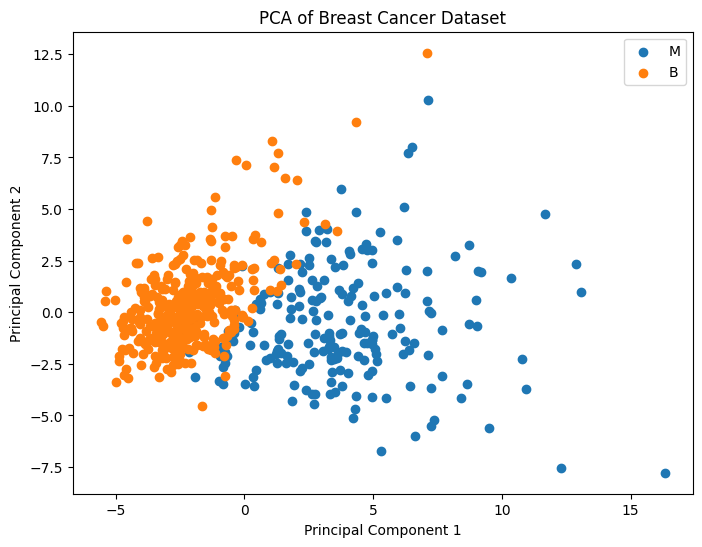

In [ ]:
plt.figure(figsize=(8, 6))

for diagnosis in pca_df["Diagnosis"].unique():

    subset = pca_df[
        pca_df["Diagnosis"] == diagnosis
    ]

    plt.scatter(
        subset["Principal Component 1"],
        subset["Principal Component 2"],
        label=diagnosis
    )


plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title(
    "PCA of Breast Cancer Dataset"
)

plt.legend()

plt.show()

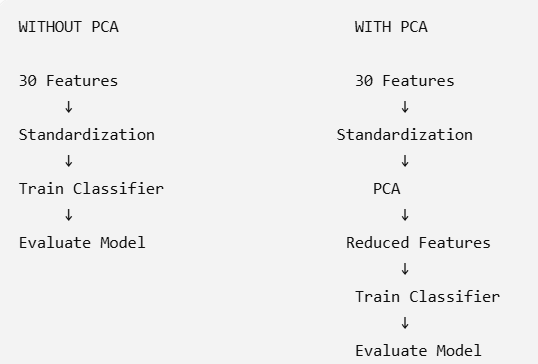

In [ ]:
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DSES LAB 26-27/breast-cancer.csv")

# Remove ID column
df = df.drop("id", axis=1)

# Features
X = df.drop("diagnosis", axis=1)

# Target
y = df["diagnosis"]

In [ ]:
y = y.map({
    "M": 1,
    "B": 0
})

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
model_without_pca = LogisticRegression(
    max_iter=10000
)

start_time = time.time()

model_without_pca.fit(
    X_train_scaled,
    y_train
)

end_time = time.time()

training_time_without_pca = (
    end_time - start_time
)

In [ ]:
y_pred_without_pca = model_without_pca.predict(
    X_test_scaled
)

accuracy_without_pca = accuracy_score(
    y_test,
    y_pred_without_pca
)

print(
    "Accuracy Without PCA:",
    accuracy_without_pca
)

print(
    "Training Time Without PCA:",
    training_time_without_pca
)

Accuracy Without PCA: 0.9649122807017544
Training Time Without PCA: 0.06545567512512207


In [ ]:
pca = PCA(
    n_components=0.95
)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

X_test_pca = pca.transform(
    X_test_scaled
)

In [ ]:
print(
    "Number of Components Selected:",
    pca.n_components_
)

Number of Components Selected: 10


In [ ]:
model_with_pca = LogisticRegression(
    max_iter=10000
)

start_time = time.time()

model_with_pca.fit(
    X_train_pca,
    y_train
)

end_time = time.time()

training_time_with_pca = (
    end_time - start_time
)

In [ ]:
y_pred_with_pca = model_with_pca.predict(
    X_test_pca
)

accuracy_with_pca = accuracy_score(
    y_test,
    y_pred_with_pca
)

print(
    "Accuracy With PCA:",
    accuracy_with_pca
)

print(
    "Training Time With PCA:",
    training_time_with_pca
)

Accuracy With PCA: 0.9736842105263158
Training Time With PCA: 0.0664060115814209


In [ ]:
results = pd.DataFrame({

    "Method": [
        "Without PCA",
        "With PCA"
    ],

    "Number of Features": [
        X_train_scaled.shape[1],
        pca.n_components_
    ],

    "Accuracy": [
        accuracy_without_pca,
        accuracy_with_pca
    ],

    "Training Time (seconds)": [
        training_time_without_pca,
        training_time_with_pca
    ]

})

print("\nComparison Results:")

print(results)


Comparison Results:
        Method  Number of Features  Accuracy  Training Time (seconds)
0  Without PCA                  30  0.964912                 0.065456
1     With PCA                  10  0.973684                 0.066406
